In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix

In [10]:
df = pd.read_csv("thyroid_dataset.csv")

In [11]:
df.head()

,Age,Sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,goitre,tumor,hypopituitary,psych,TSH,T3_measured,TT4_measured,T4U_measured,FTI_measured,Outlier_label
0,0.45,1,0,0,0,0,0,0,0,0,...,0,0,0,0,61.0,6.0,23.0,87.0,26.0,o
1,0.61,0,0,0,0,1,0,0,0,0,...,0,0,0,0,29.0,15.0,61.0,96.0,64.0,o
2,0.16,0,1,0,0,0,0,0,0,0,...,0,1,0,0,29.0,19.0,58.0,103.0,56.0,o
3,0.85,0,0,0,0,0,0,0,0,0,...,0,0,0,0,114.0,3.0,24.0,61.0,39.0,o
4,0.75,1,0,0,0,0,0,0,0,0,...,0,0,0,0,49.0,3.0,5.0,116.0,4.0,o


In [12]:
X = df.drop("Outlier_label", axis=1)
y = df["Outlier_label"]

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [24]:
# 4. Apply LOF
neighbs = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.036
)
labels = neighbs.fit_predict(X_scaled)


In [25]:
n_outliers = np.sum(labels == -1)
n_normal = np.sum(labels == 1)

print("Outliers:", n_outliers)
print("Normal:", n_normal)

Outliers: 249
Normal: 6667


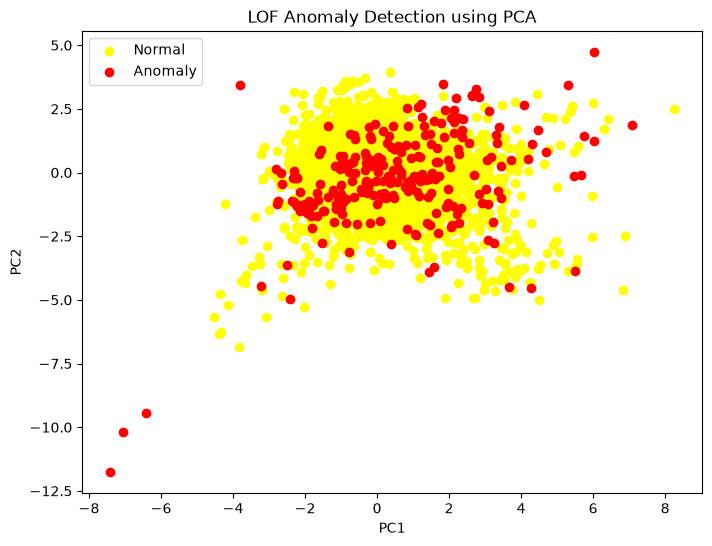

In [27]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[labels == 1, 0],
    X_pca[labels == 1, 1],
    color="yellow",
    label="Normal"
)

plt.scatter(
    X_pca[labels == -1, 0],
    X_pca[labels == -1, 1],
    color="red",
    label="Anomaly"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("LOF Anomaly Detection using PCA")
plt.legend()
plt.show()